# 11 — Model comparison diagnostics

Diagnostics for the Bayesian spectral-model comparison in `model_comparison/` (power law,
curved power law, moment expansion of order 2 and of order 3, fitted with UltraNest per TRIS ring sample on the TOD
route). Nothing here edits that module or reruns the full comparison.

* **Part 1** (always runs) reads only `model_comparison/results/evidence_per_unit_tod.csv`
  and looks at the **per-sample** log-evidence differences. No summed ln Z totals are shown:
  neighbouring ring samples are 3° apart under a ~20° beam, so they are strongly correlated
  and a sum would overstate the evidence.
* **Part 2** (`RUN_RERUNS`) reruns the four models for a few samples to
  get what the original run did not save: posteriors, best fits and maximum likelihoods.
* **Part 3** (`RUN_PRIOR_SENSITIVITY`) reruns the curved power law with a
  narrower prior on the curvature C, to see how much its evidence depends on that prior.
* **Part 4** (`RUN_CONVERGENCE`) checks that UltraNest's ln Z has converged: against an exact grid
  integral, over seeds, live points and the stopping rule.

Reruns use the same `config.yaml`, priors, UltraNest settings and error table
(`error_bars.csv`) and ring TODs (`sed.tod_beam`) as `run_comparison.py`, and are cached in
`model_comparison/diagnostic_plots/cache/`, so a cached sample is never rerun.
Every figure is shown here and saved as a PNG in `model_comparison/diagnostic_plots/`.

## Settings
All paths, sample numbers and flags. Switch a flag to `True` to run that part.

In [70]:
%matplotlib inline
import os
os.environ.setdefault("TQDM_DISABLE", "1")
import sys
import copy
import logging
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpecFromSubplotSpec

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
MC_DIR = REPO / "model_comparison"
CSV_PATH = MC_DIR / "results" / "evidence_per_unit_tod.csv"
CONFIG_PATH = MC_DIR / "config.yaml"
ERRORS_CSV = MC_DIR / "error_bars.csv"
PLOT_DIR = MC_DIR / "diagnostic_plots"
CACHE_DIR = PLOT_DIR / "cache"

# ---- flags ----
RUN_RERUNS = True               # Part 2: rerun the four models for RERUN_UNITS
RUN_PRIOR_SENSITIVITY = True    # Part 3: rerun the curved power law with narrower C priors
RUN_CONVERGENCE = True          # Part 4: convergence tests of the evidence (about 5 min, cached)

# ---- samples (TOD-route unit = TRIS ring sample index; its RA is read from the CSV) ----
RERUN_UNITS = [0, 40, 75, 89, 100, 102]
SENS_UNITS = [0, 40, 75, 100, 102]
C_HALF_WIDTHS = [0.5, 0.2, 0.1]  # 0.5 is config.yaml's prior; the others override it here
CONV_UNITS = [0, 89, 102]        # Part 4: a tie (0), a power-law win (89), a curved win at Cygnus (102)
CONV_SEEDS = [1, 2, 3, 4, 5]     # Part 4: repeat runs at the default settings
CONV_LIVE = [100, 1600]          # Part 4: live points tried besides config.yaml's default (400)
CONV_STRICT_DLOGZ = 0.1          # Part 4: a stricter stopping rule than config.yaml's 0.5
# Part 4: grid points per axis for the exact integral, by number of parameters (two per model, to show it
# has converged).  The 4-parameter order-3 model uses fewer points per axis: 81^4 would be 43 million points.
GRID_N = {2: [41, 81], 3: [41, 81], 4: [25, 41]}

# ---- reading the evidence ----
TIE = 1.0                        # |dlogZ| < 1: indistinguishable
STRONG = 2.0                     # |dlogZ| > 2: strong
CYG_A_RA = 299.9                 # deg
N_CURVE_SAMPLES = 1000           # posterior draws used for the model bands

PL, CURVED = "power law", "curved power law"
MOMENT, MOMENT3 = "moment expansion (order 2)", "moment expansion (order 3)"
ALL4 = (PL, CURVED, MOMENT, MOMENT3)
SHORT = {PL: "power law", CURVED: "curved PL", MOMENT: "moment (2nd order)", MOMENT3: "moment (3rd order)"}
# Okabe-Ito, colourblind-safe
COL = {PL: "#0072B2", CURVED: "#D55E00", MOMENT: "#009E73", MOMENT3: "#CC79A7"}
UNIT_COLS = ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#56B4E9", "#D55E00"]
# 5-class diverging (PuOr, colourblind-safe), grey midpoint
CLASS_COLS = ["#542788", "#998ec3", "#d9d9d9", "#f1a340", "#b35806"]
POINT_NAMES = {"TRIS_600": "TRIS 600", "TRIS_820": "TRIS 820", "LWA_35MHz.fits": "LWA 35",
               "MAIPU_45mhZ.fits": "Maipu 45", "LWA_80MHz.fits": "LWA 80",
               "STOCKERT_VILLA_1400MHZ.fits": "Stockert 1420"}

plt.rcParams.update({"figure.dpi": 110, "font.size": 12, "axes.titlesize": 13,
                     "axes.labelsize": 12, "legend.fontsize": 10, "figure.facecolor": "white"})
PLOT_DIR.mkdir(exist_ok=True)

def save(fig, name):
    """Save a figure as PNG in PLOT_DIR, then show it inline."""
    fig.savefig(PLOT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()
    print(f"saved {(PLOT_DIR / f'{name}.png').relative_to(REPO)}")

# Part 1 — per-sample evidence from the saved CSV

In [71]:
ev = pd.read_csv(CSV_PATH).sort_values("ra_deg").reset_index(drop=True)
lz = {m: ev[f"logZ {m}"].to_numpy() for m in ALL4}
lze = {m: ev[f"logZerr {m}"].to_numpy() for m in ALL4}
ra = ev["ra_deg"].to_numpy()
RA_OF = dict(zip(ev["unit"], ev["ra_deg"]))

def diff(a, b):
    return lz[a] - lz[b], np.hypot(lze[a], lze[b])

dC, dC_err = diff(CURVED, PL)       # curved - power law
dM, dM_err = diff(MOMENT, PL)       # moment - power law
dM3, dM3_err = diff(MOMENT3, PL)    # moment (order 3) - power law
dMC, dMC_err = diff(MOMENT, CURVED) # moment - curved
dM32, dM32_err = diff(MOMENT3, MOMENT)  # moment order 3 - order 2

print(f"{CSV_PATH.relative_to(REPO)}: {len(ev)} ring samples, RA {ra.min():.0f}-{ra.max():.0f} deg")
print(f"points per sample: {sorted(ev['n_points'].unique())}")
print(f"ln Z error per sample (median): " + ", ".join(f"{SHORT[m]} {np.median(lze[m]):.2f}" for m in lz))
print(f"error on a difference (median): dC {np.median(dC_err):.2f}, dM {np.median(dM_err):.2f}, dM3 {np.median(dM3_err):.2f}")

model_comparison/results/evidence_per_unit_tod.csv: 120 ring samples, RA 0-357 deg
points per sample: [np.int64(4)]
ln Z error per sample (median): power law 0.22, curved PL 0.23, moment (2nd order) 0.22, moment (3rd order) 0.22
error on a difference (median): dC 0.31, dM 0.32, dM3 0.31


### Figure 1 — evidence difference along the ring
One panel per extra-parameter model (curved power law, moment expansion of order 2 and of order 3).
Each point is one TRIS ring sample: above zero the extra-parameter model has more evidence than the
power law, below zero the power law wins. The grey band (|ΔlnZ| < 1) means the two cannot be told
apart, the faint lines at ±2 mark strong preference, and the dotted line is Cygnus A.

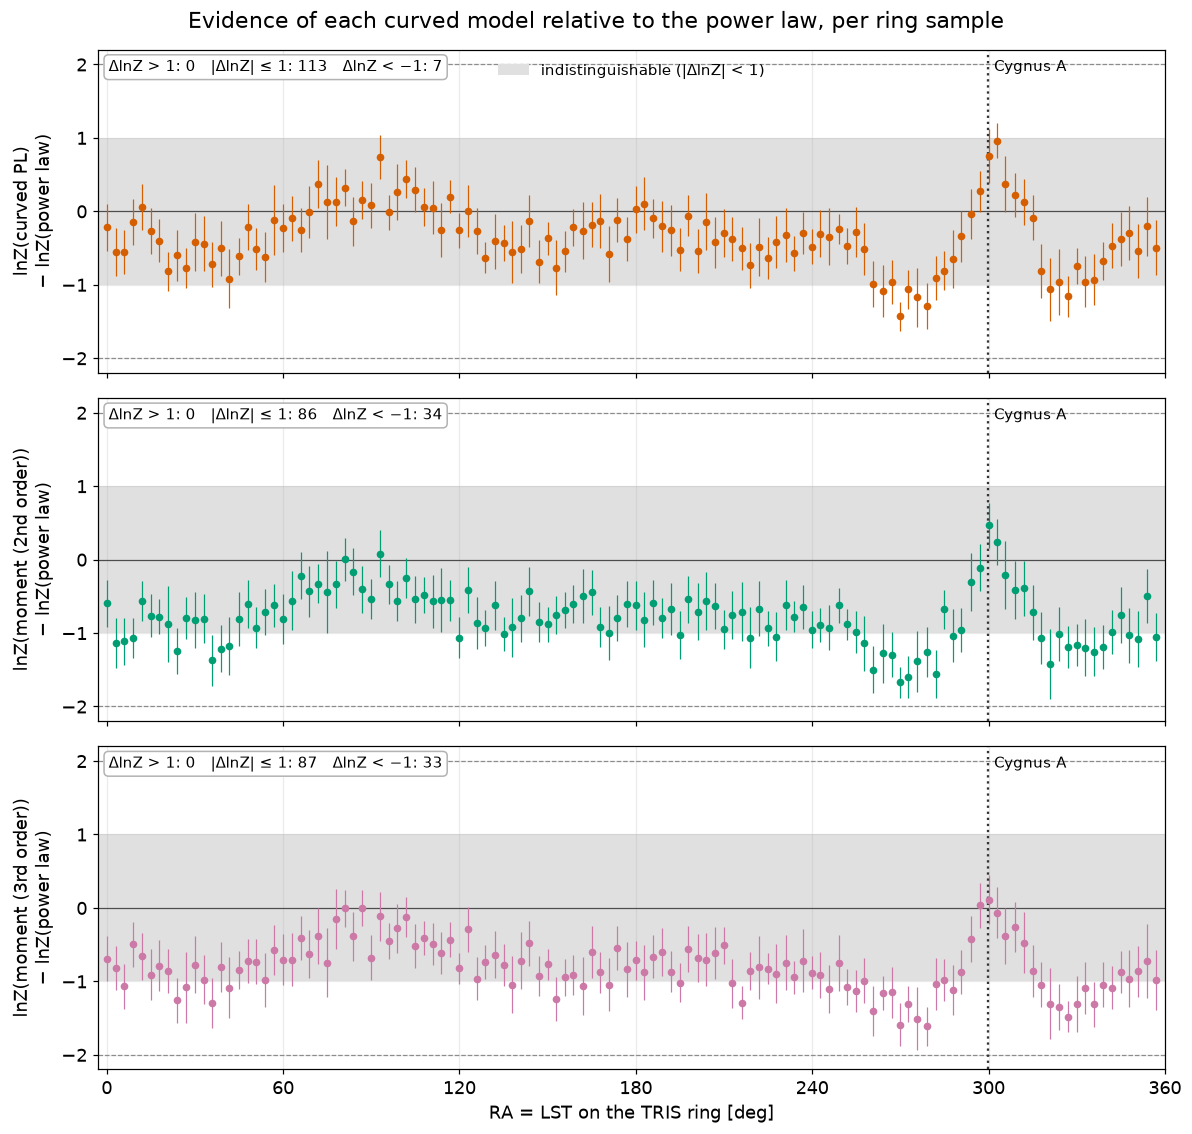

saved model_comparison/diagnostic_plots/fig1_dlogZ_vs_ra.png


In [72]:
def counts3(d):
    return int((d > TIE).sum()), int((np.abs(d) <= TIE).sum()), int((d < -TIE).sum())

fig, axes = plt.subplots(3, 1, figsize=(11, 10.5), sharex=True)
for ax, d, e, m in zip(axes, (dC, dM, dM3), (dC_err, dM_err, dM3_err), (CURVED, MOMENT, MOMENT3)):
    ax.axhspan(-TIE, TIE, color="0.88", lw=0, label="indistinguishable (|ΔlnZ| < 1)")
    for y in (-STRONG, STRONG):
        ax.axhline(y, color="0.55", lw=0.8, ls="--")
    ax.axhline(0, color="0.3", lw=0.8)
    ax.errorbar(ra, d, yerr=e, fmt="o", ms=4, color=COL[m], ecolor=COL[m], elinewidth=0.8, capsize=0)
    ax.axvline(CYG_A_RA, color="0.2", ls=":", lw=1.5)
    ax.text(CYG_A_RA + 2, 0.97, "Cygnus A", transform=ax.get_xaxis_transform(), va="top", fontsize=10)
    up, tie, down = counts3(d)
    ax.text(0.01, 0.97, f"ΔlnZ > 1: {up}   |ΔlnZ| ≤ 1: {tie}   ΔlnZ < −1: {down}",
            transform=ax.transAxes, va="top", fontsize=10,
            bbox=dict(fc="white", ec="0.7", boxstyle="round,pad=0.3"))
    ax.set_ylabel(f"lnZ({SHORT[m]})\n− lnZ(power law)")
    ax.grid(alpha=0.25)
axes[0].legend(loc="upper center", frameon=False)
axes[-1].set_xlabel("RA = LST on the TRIS ring [deg]")
axes[-1].set_xlim(-3, 360); axes[-1].set_xticks(np.arange(0, 361, 60))
fig.suptitle("Evidence of each curved model relative to the power law, per ring sample")
fig.tight_layout()
save(fig, "fig1_dlogZ_vs_ra")

### Figure 2 — absolute log-evidence along the ring
The four models' ln Z for every ring sample on one axis. The overall level follows how well the
data constrain each sample (mostly the error-bar normalisation), so read the gaps between the
lines, not their height.

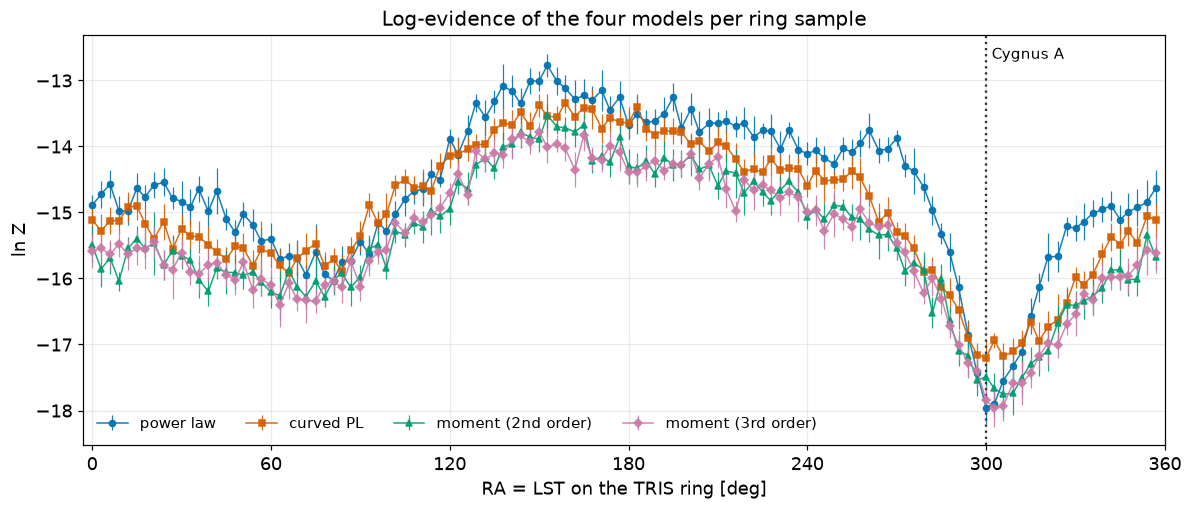

saved model_comparison/diagnostic_plots/fig2_logZ_vs_ra.png


In [73]:
fig, ax = plt.subplots(figsize=(11, 4.8))
for m, mk in zip(ALL4, ("o", "s", "^", "D")):
    ax.errorbar(ra, lz[m], yerr=lze[m], fmt=mk + "-", ms=4, lw=1, color=COL[m], label=SHORT[m],
                elinewidth=0.8, alpha=0.9)
ax.axvline(CYG_A_RA, color="0.2", ls=":", lw=1.5)
ax.text(CYG_A_RA + 2, 0.97, "Cygnus A", transform=ax.get_xaxis_transform(), va="top", fontsize=10)
ax.set_xlabel("RA = LST on the TRIS ring [deg]"); ax.set_ylabel("ln Z")
ax.set_xlim(-3, 360); ax.set_xticks(np.arange(0, 361, 60))
ax.legend(frameon=False, ncol=4, loc="lower left"); ax.grid(alpha=0.25)
ax.set_title("Log-evidence of the four models per ring sample")
fig.tight_layout()
save(fig, "fig2_logZ_vs_ra")

### Figure 3 — distribution of the evidence differences
Histograms of ΔlnZ over the 120 ring samples, for the curved power law and the moment expansion
(orders 2 and 3) against the power law. The grey band is the indistinguishable range, the solid line is zero and
the dashed line the median.

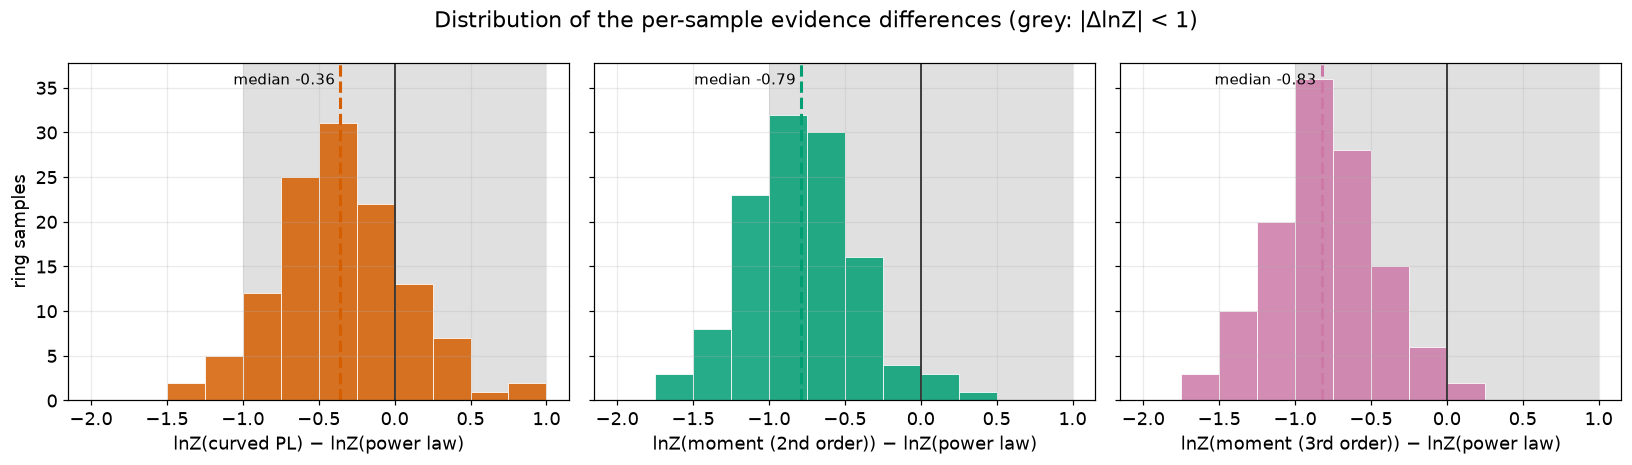

saved model_comparison/diagnostic_plots/fig3_dlogZ_histograms.png


In [74]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), sharey=True)
lo = np.floor(min(dC.min(), dM.min(), dM3.min())); hi = np.ceil(max(dC.max(), dM.max(), dM3.max()))
bins = np.arange(lo, hi + 0.25, 0.25)
for ax, d, m in zip(axes, (dC, dM, dM3), (CURVED, MOMENT, MOMENT3)):
    ax.axvspan(-TIE, TIE, color="0.88", lw=0)
    ax.hist(d, bins=bins, color=COL[m], alpha=0.85, edgecolor="white", linewidth=0.6)
    ax.axvline(0, color="0.2", lw=1.2)
    med = np.median(d)
    ax.axvline(med, color=COL[m], lw=2, ls="--")
    ax.text(med, 0.97, f" median {med:+.2f} ", transform=ax.get_xaxis_transform(), va="top",
            ha="right" if med < 0 else "left", fontsize=10)
    ax.set_xlabel(f"lnZ({SHORT[m]}) − lnZ(power law)")
    ax.grid(alpha=0.25)
axes[0].set_ylabel("ring samples")
fig.suptitle("Distribution of the per-sample evidence differences (grey: |ΔlnZ| < 1)")
fig.tight_layout()
save(fig, "fig3_dlogZ_histograms")

### Figure 4 — how often each model is preferred
For each pair (A vs B) the bar splits the 120 ring samples by ΔlnZ = lnZ(A) − lnZ(B): purple means A
is favoured, orange that B is, and grey that they cannot be told apart. Read the bar's colour balance;
the numbers are sample counts.

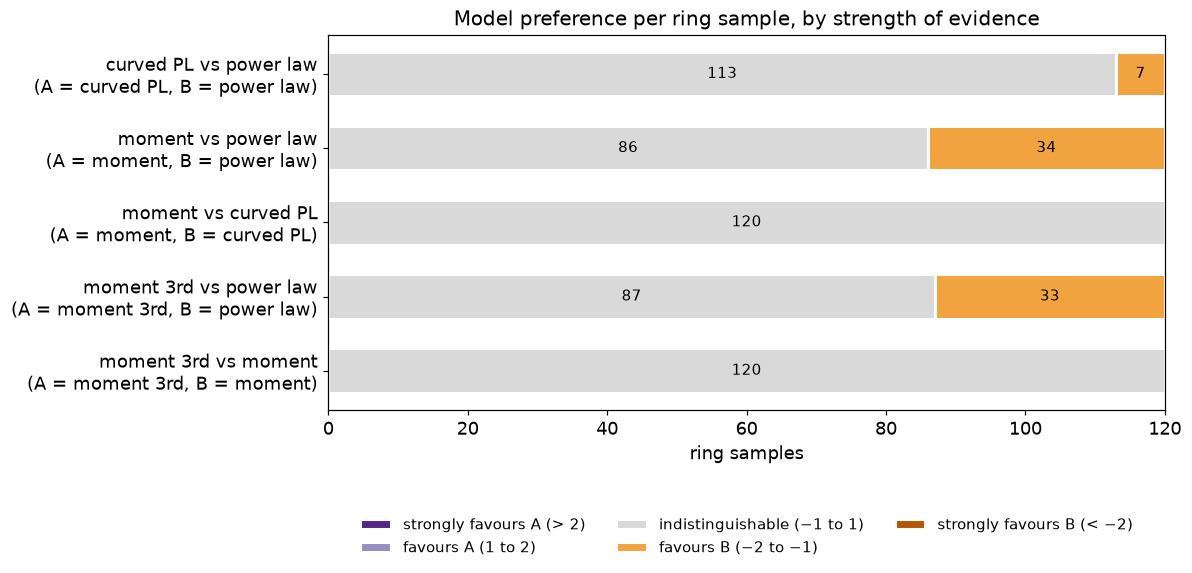

saved model_comparison/diagnostic_plots/fig4_preference_counts.png
                         strongly favours A (> 2)  favours A (1 to 2)  indistinguishable (−1 to 1)  favours B (−2 to −1)  strongly favours B (< −2)
curved PL vs power law                          0                   0                          113                     7                          0
moment vs power law                             0                   0                           86                    34                          0
moment vs curved PL                             0                   0                          120                     0                          0
moment 3rd vs power law                         0                   0                           87                    33                          0
moment 3rd vs moment                            0                   0                          120                     0                          0


In [75]:
CLASSES = [("strongly favours A (> 2)", lambda d: d > STRONG),
           ("favours A (1 to 2)", lambda d: (d > TIE) & (d <= STRONG)),
           ("indistinguishable (−1 to 1)", lambda d: np.abs(d) <= TIE),
           ("favours B (−2 to −1)", lambda d: (d < -TIE) & (d >= -STRONG)),
           ("strongly favours B (< −2)", lambda d: d < -STRONG)]
PAIRS = [("curved PL vs power law", dC), ("moment vs power law", dM), ("moment vs curved PL", dMC),
         ("moment 3rd vs power law", dM3), ("moment 3rd vs moment", dM32)]   # "moment" = 2nd order
table = pd.DataFrame({lab: [int(f(d).sum()) for _, d in PAIRS] for lab, f in CLASSES},
                     index=[p for p, _ in PAIRS])
assert (table.sum(axis=1) == len(ev)).all()

fig, ax = plt.subplots(figsize=(11, 5.6))
y = np.arange(len(PAIRS))[::-1]
left = np.zeros(len(PAIRS))
for (lab, _), c in zip(CLASSES, CLASS_COLS):
    w = table[lab].to_numpy()
    ax.barh(y, w, left=left, color=c, edgecolor="white", linewidth=2, height=0.6, label=lab)
    for yi, li, wi in zip(y, left, w):
        if wi >= 4:
            ax.text(li + wi / 2, yi, str(wi), ha="center", va="center", fontsize=10,
                    color="white" if c in (CLASS_COLS[0], CLASS_COLS[4]) else "black")
    left += w
ax.set_yticks(y); ax.set_yticklabels([f"{p}\n(A = {p.split(' vs ')[0]}, B = {p.split(' vs ')[1]})" for p, _ in PAIRS])
ax.set_xlim(0, len(ev)); ax.set_xlabel("ring samples")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.25), frameon=False)
ax.set_title("Model preference per ring sample, by strength of evidence")
fig.tight_layout()
save(fig, "fig4_preference_counts")
print(table.to_string())

# Part 2 — posteriors, best fits and maximum likelihood (reruns)

**What the original run saved.** `run_comparison.py` writes, per sample, only the sample index,
RA, number of points, the inputs used, and ln Z ± error for each model. It keeps no best-fit
parameters, no maximum log-likelihood and no posterior samples, and `sampler.log_dir` is `null`, so
UltraNest wrote nothing to disk. The next cell checks this, and then (only if `RUN_RERUNS = True`)
reruns the four models for `RERUN_UNITS` and caches each result.

In [76]:
with open(CONFIG_PATH) as f:
    cfg = yaml.safe_load(f)
saved_cols = list(ev.columns)
log_dir = cfg["sampler"].get("log_dir")
sample_files = (sorted(Path(log_dir).rglob("equal_weighted_post.txt")) if log_dir and Path(log_dir).exists() else [])
extra = [c for c in saved_cols if not c.startswith(("logZ ", "logZerr "))]
print("columns saved per sample:", ", ".join(extra), "+ logZ and logZerr per model")
print("best-fit parameters saved:   ", any("best" in c or "beta" in c for c in saved_cols))
print("max log-likelihood saved:    ", any("logl" in c.lower() or "maxl" in c.lower() for c in saved_cols))
print(f"posterior samples on disk:    {bool(sample_files)}  (sampler.log_dir = {log_dir!r})")
POSTERIORS_SAVED = bool(sample_files)
if POSTERIORS_SAVED:
    print("Posterior files found: NOTE run_comparison reuses one log_dir for every sample and model, "
          "so only the last run's files survive. Not used here.")

columns saved per sample: unit, ra_deg, n_points, inputs + logZ and logZerr per model
best-fit parameters saved:    False
max log-likelihood saved:     False
posterior samples on disk:    False  (sampler.log_dir = None)


In [77]:
sys.dont_write_bytecode = True                   # leave no __pycache__ in model_comparison/
sys.path.insert(0, str(REPO / "src"))
sys.path.insert(0, str(MC_DIR))
# Drop repo modules a long-running kernel loaded earlier, so the imports below read the current files
# (otherwise e.g. sed_prototype.tod_method_key, added on 2026-10-27, is missing until a kernel restart).
for _name in [n for n in sys.modules if n.split(".")[0] in ("moonrunes", "models", "run_comparison")]:
    del sys.modules[_name]
from models import build_models, prior_transform
import run_comparison as rc                      # imported for its data helpers; main() is not run
from moonrunes.config import load_config
from moonrunes.sed_prototype import tod_method_key
# How the ring TODs are made (run_config.yaml sed.tod_beam, beam-matched since 2026-10-27).  Cached results
# made from other TODs do not match it and are redone.
TOD_KEY = tod_method_key(load_config(REPO / "configs" / "run_config.yaml"))

ALL_MODELS = build_models(cfg)
# The four models diagnosed here; config.yaml's models.moment_orders must include both 2 and 3.
assert set(ALL4) <= set(ALL_MODELS), list(ALL_MODELS)
MODELS = {m: ALL_MODELS[m] for m in ALL4}
SCFG = cfg["sampler"]
# Moment expansion: beta fixed at config.yaml's models.moment_beta_fixed (omega1 free), or free if null.
BETA_FIX = cfg["models"].get("moment_beta_fixed")
TAG = {PL: "base", CURVED: "base"} | {m: "base" if BETA_FIX is None else f"beta{float(BETA_FIX):g}" for m in (MOMENT, MOMENT3)}
print("moment expansion:", "beta free, omega1 = 0" if BETA_FIX is None else f"beta fixed at {float(BETA_FIX):g}, omega1 free")
assert cfg["priors"]["C"]["type"] == "uniform" and -cfg["priors"]["C"]["low"] == cfg["priors"]["C"]["high"] == 0.5

def slug(s):
    return "".join(ch if ch.isalnum() else "_" for ch in s).strip("_")

def cache_path(unit, model, tag):
    return CACHE_DIR / f"unit{unit:03d}__{slug(model)}__{tag}.npz"

_INP = None
def get_inputs():
    """The TOD-route inputs (built once, takes a few minutes)."""
    global _INP
    if _INP is None:
        from moonrunes.config import load_config
        from moonrunes.sed_prototype import Inputs
        print("building the TOD-route inputs (takes a few minutes)...")
        _INP = Inputs(load_config(REPO / "configs" / "run_config.yaml"), REPO / "res",
                      target_file=cfg["data"]["target_file"], verbose=False)
    return _INP

_POINTS = {}
def unit_points(units):
    """(nu, t, s, keys) per unit, built exactly as run_comparison does (TOD route)."""
    need = [u for u in units if u not in _POINTS]
    if need:
        errors = rc.read_error_bars(ERRORS_CSV)
        inp = get_inputs()
        for uid, _, pts in rc.tod_units(inp, errors):
            if uid in need:
                pts = rc.usable(pts)
                _POINTS[uid] = (np.array([q[1] for q in pts]), np.array([q[2] for q in pts]),
                                np.array([q[3] for q in pts]), [q[0] for q in pts])
    return {u: _POINTS[u] for u in units}

def run_nested(model, priors, nu, t, s):
    """The same likelihood and UltraNest call as rc.log_evidence, keeping the posterior."""
    import ultranest
    names, fn = MODELS[model]
    transform = prior_transform(names, priors)
    norm = -np.sum(np.log(s * np.sqrt(2 * np.pi)))
    def loglike(params):
        r = (t - fn(nu, params)) / s
        return -0.5 * np.sum(r * r, axis=-1) + norm
    sampler = ultranest.ReactiveNestedSampler(names, loglike, transform, vectorized=True,
                                              log_dir=SCFG.get("log_dir"))
    logging.getLogger("ultranest").setLevel(logging.WARNING)
    res = sampler.run(min_num_live_points=int(SCFG["min_num_live_points"]), dlogz=float(SCFG["dlogz"]),
                      show_status=False, viz_callback=False)
    return dict(logz=res["logz"], logzerr=res["logzerr"], samples=res["samples"],
                maxlogl=res["maximum_likelihood"]["logl"], maxpoint=np.asarray(res["maximum_likelihood"]["point"]),
                names=np.array(names))

def get_results(units, model, tag, priors, allow_run):
    """{unit: result} from the cache; missing ones are run only if allow_run."""
    out, missing = {}, []
    for u in units:
        p = cache_path(u, model, tag)
        z = np.load(p, allow_pickle=False) if p.exists() else None
        if z is not None and "tod_key" in z.files and str(z["tod_key"]) == TOD_KEY:   # from the current TODs
            out[u] = {k: z[k] for k in z.files}
        else:
            missing.append(u)
    if missing and allow_run:
        CACHE_DIR.mkdir(parents=True, exist_ok=True)
        logging.getLogger("ultranest").setLevel(logging.WARNING)
        for u, (nu, t, s, keys) in unit_points(missing).items():
            r = run_nested(model, priors, nu, t, s)
            r.update(nu=nu, t=t, s=s, keys=np.array(keys), unit=u, tag=tag, tod_key=TOD_KEY)
            np.savez(cache_path(u, model, tag), **r)
            out[u] = r
            print(f"  ran unit {u:3d}, {SHORT[model]:<20} [{tag}]  lnZ = {r['logz']:.2f} ± {r['logzerr']:.2f}")
    return out

HASLAM_CACHE = CACHE_DIR / "haslam_tod.npz"
def haslam_points(allow_run):
    """Haslam (the target map, NOT a fit point) through the TRIS beam, per ring sample, for plotting only."""
    z = np.load(HASLAM_CACHE, allow_pickle=False) if HASLAM_CACHE.exists() else None
    if z is not None and "tod_key" in z.files and str(z["tod_key"]) == TOD_KEY:   # from the current TODs
        return {k: z[k] for k in z.files}
    if not allow_run:
        return None
    from moonrunes.sky_maps import rj_excess
    from moonrunes.sed_prototype import sigma_for
    inp = get_inputs(); m = inp.target; d = inp.tods[m["name"]]
    t = np.array([float(rj_excess(v, m)) for v in d["tod"]])
    out = dict(nu=float(m["freq_mhz"]), t=t, s=np.asarray(sigma_for(m, t), dtype=float),
               good=np.asarray(d["good"], dtype=bool), map_file=str(m["file"]), tod_key=TOD_KEY)   # not "file": that is np.savez's own argument
    CACHE_DIR.mkdir(parents=True, exist_ok=True)
    np.savez(HASLAM_CACHE, **out)
    return out

P2 = {m: get_results(RERUN_UNITS, m, TAG[m], cfg["priors"], RUN_RERUNS) for m in MODELS}
HAS = haslam_points(RUN_RERUNS)
P2_UNITS = [u for u in RERUN_UNITS if all(u in P2[m] for m in MODELS)]
if not P2_UNITS:
    print("PART 2 SKIPPED: no cached reruns found and RUN_RERUNS = False. "
          "Set RUN_RERUNS = True in the settings cell to rerun units", RERUN_UNITS)
else:
    print(f"Part 2 results available for units {P2_UNITS}"
          + ("" if len(P2_UNITS) == len(RERUN_UNITS) else f" (missing: {sorted(set(RERUN_UNITS) - set(P2_UNITS))})"))
    print("\nrerun lnZ against the saved CSV (UltraNest is not seeded, so expect agreement within the errors):")
    for u in P2_UNITS:
        row = ev.set_index("unit").loc[u]
        print(f"  unit {u:3d}: " + "   ".join(
            f"{SHORT[m]} {float(P2[m][u]['logz']):+.2f} vs {row[f'logZ {m}']:+.2f}" for m in MODELS))

moment expansion: beta fixed at -2.7, omega1 free
building the TOD-route inputs (takes a few minutes)...
  ran unit   0, moment (3rd order)   [beta-2.7]  lnZ = -15.68 ± 0.17
  ran unit  40, moment (3rd order)   [beta-2.7]  lnZ = -14.89 ± 0.24
  ran unit  75, moment (3rd order)   [beta-2.7]  lnZ = -14.37 ± 0.22
  ran unit  89, moment (3rd order)   [beta-2.7]  lnZ = -15.56 ± 0.15
  ran unit 100, moment (3rd order)   [beta-2.7]  lnZ = -17.93 ± 0.26
  ran unit 102, moment (3rd order)   [beta-2.7]  lnZ = -17.65 ± 0.37
Part 2 results available for units [0, 40, 75, 89, 100, 102]

rerun lnZ against the saved CSV (UltraNest is not seeded, so expect agreement within the errors):
  unit   0: power law -14.85 vs -14.89   curved PL -15.21 vs -15.11   moment (2nd order) -15.37 vs -15.49   moment (3rd order) -15.68 vs -15.58
  unit  40: power law -14.11 vs -13.88   curved PL -14.39 vs -14.14   moment (2nd order) -14.91 vs -14.95   moment (3rd order) -14.89 vs -14.70
  unit  75: power law -14.13 vs -

### Figure 5 — data and fitted models for the rerun samples
Each panel is one ring sample: the six SED points (CMB-free Rayleigh–Jeans temperature) with their
error bars, and each model's posterior median with its 68% band (none for the curved power law), for all four models.
Haslam 408 MHz (open diamond) is plotted for comparison only and is not used in any fit. The small panel below shows the
residuals, data minus model in units of σ, for the power law and the curved power law.

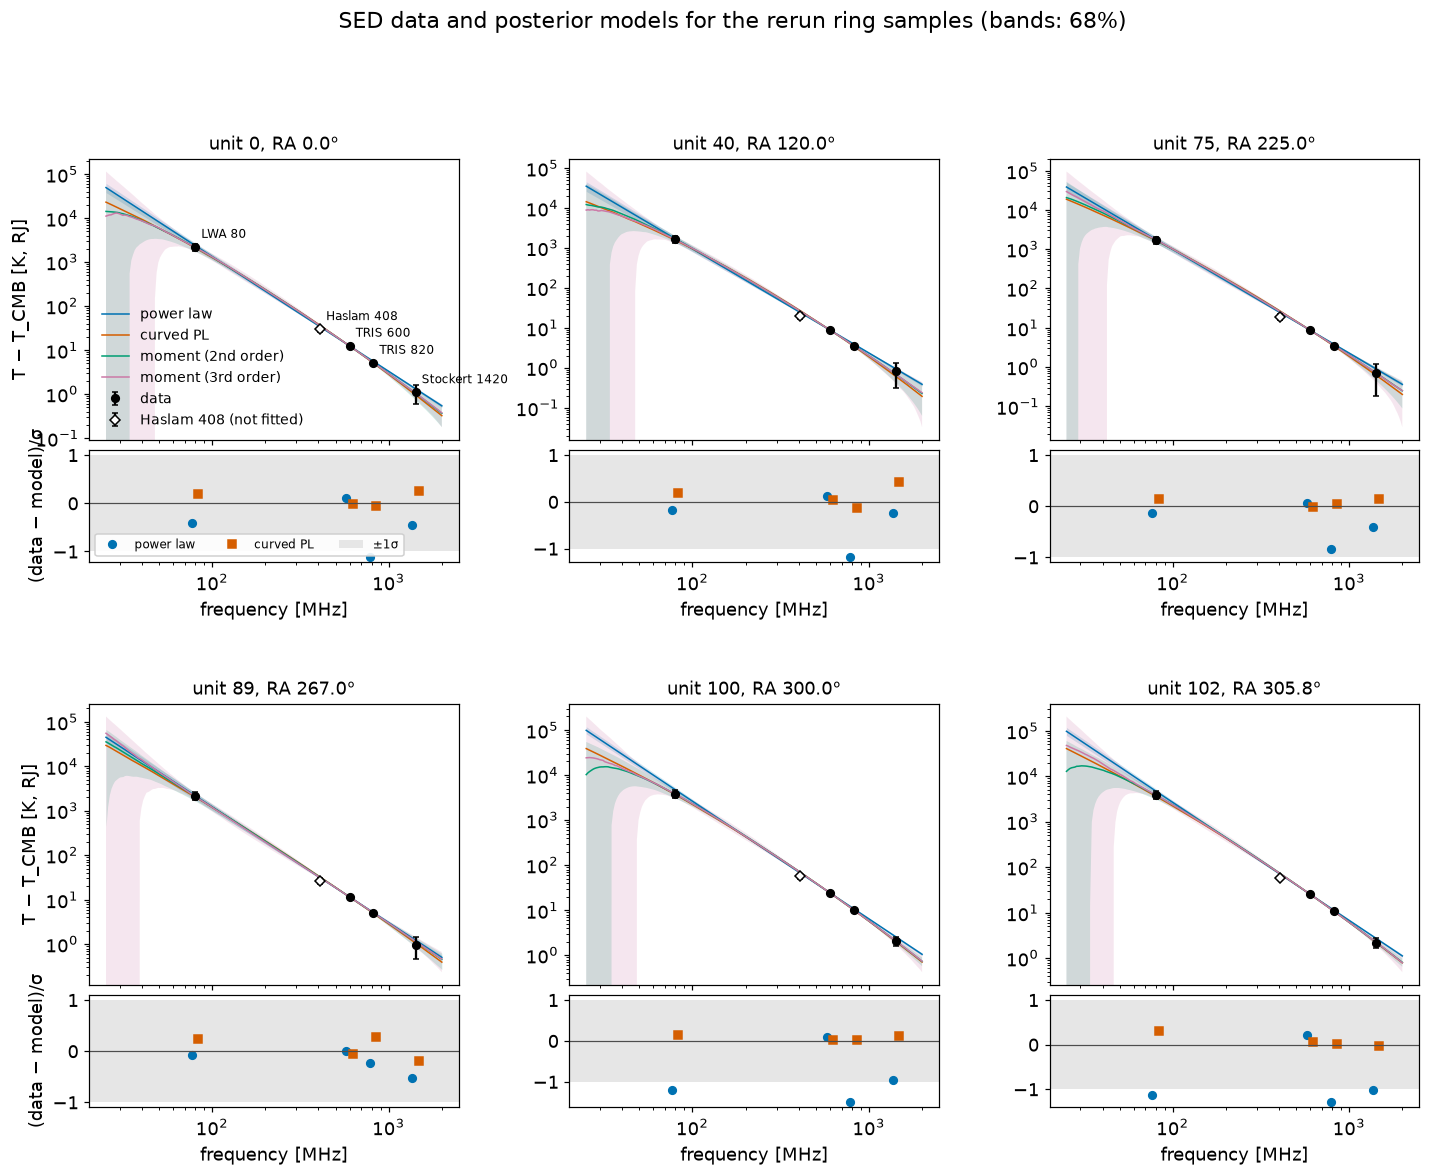

saved model_comparison/diagnostic_plots/fig5_sed_fits_per_unit.png


In [78]:
def model_band(model, samples, nu):
    names, fn = MODELS[model]
    rng = np.random.default_rng(0)
    sel = samples if len(samples) <= N_CURVE_SAMPLES else samples[rng.choice(len(samples), N_CURVE_SAMPLES, replace=False)]
    curves = fn(nu, sel)
    return np.percentile(curves, [16, 50, 84], axis=0)

if not P2_UNITS:
    print("Figure 5 skipped: no Part 2 results (set RUN_RERUNS = True).")
else:
    ncol = 3; nrow = int(np.ceil(len(P2_UNITS) / ncol))
    fig = plt.figure(figsize=(5.2 * ncol, 5.6 * nrow))
    outer = fig.add_gridspec(nrow, ncol, hspace=0.35, wspace=0.3)
    grid = np.geomspace(25, 2000, 200)
    for i, u in enumerate(P2_UNITS):
        g = GridSpecFromSubplotSpec(2, 1, subplot_spec=outer[i // ncol, i % ncol], height_ratios=[3, 1.2], hspace=0.05)
        ax = fig.add_subplot(g[0]); axr = fig.add_subplot(g[1], sharex=ax)
        r0 = P2[PL][u]; nu, t, s, keys = r0["nu"], r0["t"], r0["s"], [str(k) for k in r0["keys"]]
        for m in MODELS:
            lo_, med_, hi_ = model_band(m, P2[m][u]["samples"], grid)
            if m != CURVED:   # no band for the curved power law
                ax.fill_between(grid, lo_, hi_, color=COL[m], alpha=0.18, lw=0)
            ax.plot(grid, med_, color=COL[m], lw=1.0, label=SHORT[m])
        ax.errorbar(nu, t, yerr=s, fmt="o", color="black", ms=5, capsize=2, zorder=5, label="data")
        if HAS is not None and bool(HAS["good"][u]):   # plotted only, not in any fit
            hn, ht, hs = float(HAS["nu"]), float(HAS["t"][u]), float(HAS["s"][u])
            ax.errorbar(hn, ht, yerr=hs, fmt="D", ms=5, mfc="white", mec="black", ecolor="black",
                        capsize=2, zorder=6, label="Haslam 408 (not fitted)")
            if i == 0:
                ax.annotate("Haslam 408", (hn, ht), xytext=(4, 6), textcoords="offset points", fontsize=8)
        if i == 0:
            for n_, t_, k_ in zip(nu, t, keys):
                ax.annotate(POINT_NAMES.get(k_, k_), (n_, t_), xytext=(4, 6), textcoords="offset points", fontsize=8)
        ax.set_xscale("log"); ax.set_yscale("log")
        ax.set_title(f"unit {u}, RA {RA_OF[u]:.1f}°", fontsize=12)
        ax.tick_params(labelbottom=False); #ax.grid(alpha=0.25, which="both")
        if i % ncol == 0:
            ax.set_ylabel("T − T_CMB [K, RJ]")
        for m, off, mk in ((PL, 0.96, "o"), (CURVED, 1.04, "s")):
            _, med_at, _ = model_band(m, P2[m][u]["samples"], nu)
            axr.plot(nu * off, (t - med_at) / s, mk, color=COL[m], ms=5, label=SHORT[m])
        axr.axhspan(-1, 1, color="0.9", lw=0, label="±1σ"); axr.axhline(0, color="0.3", lw=0.8)
        if i == 0:
            axr.legend(loc="lower left", fontsize=8, ncol=3, frameon=True, framealpha=0.9)
        axr.set_xscale("log"); #axr.grid(alpha=0.25)
        if i % ncol == 0:
            axr.set_ylabel("(data − model)/σ")
        axr.set_xlabel("frequency [MHz]")
    fig.axes[0].legend(loc="lower left", fontsize=9, frameon=False)
    fig.suptitle("SED data and posterior models for the rerun ring samples (bands: 68%)", y=1.0)
    save(fig, "fig5_sed_fits_per_unit")

### Figure 6 — better fit or Occam penalty?
Left: for the curved power law and the moment expansion (orders 2 and 3), how much higher their best-fit log-likelihood
is than the power law's (hatched) and how much higher their evidence is (solid); a big gain in fit
with no gain in evidence means the extra parameter is paid for by its prior. Right: each model's Occam
penalty, max lnL − lnZ, which grows with the prior volume the data rule out.

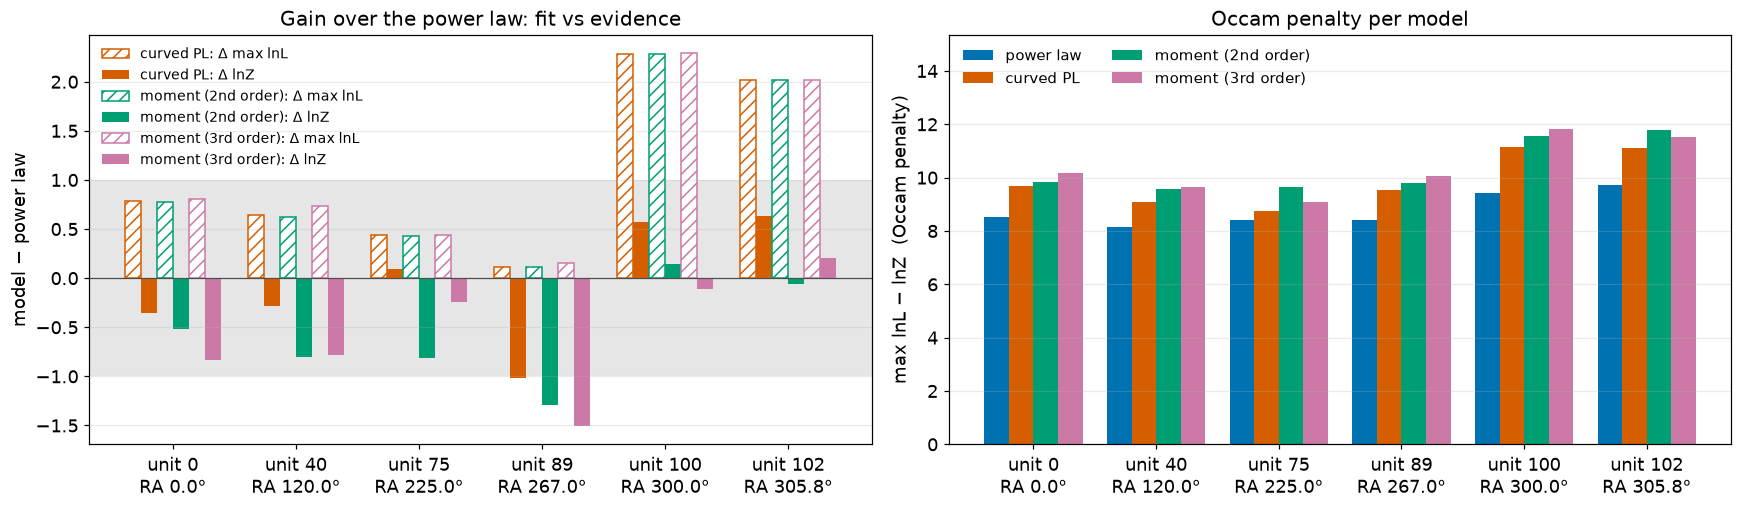

saved model_comparison/diagnostic_plots/fig6_maxlogl_vs_logZ.png
     power law max lnL  curved PL max lnL  moment (2nd order) max lnL  moment (3rd order) max lnL  power law lnZ  curved PL lnZ  moment (2nd order) lnZ  moment (3rd order) lnZ
0                -6.33              -5.54                       -5.55                       -5.52         -14.85         -15.21                  -15.37                  -15.68
40               -5.96              -5.31                       -5.33                       -5.23         -14.11         -14.39                  -14.91                  -14.89
75               -5.72              -5.28                       -5.29                       -5.28         -14.13         -14.04                  -14.95                  -14.37
89               -5.66              -5.54                       -5.55                       -5.51         -14.06         -15.07                  -15.35                  -15.56
100              -8.41              -6.12              

In [79]:
if not P2_UNITS:
    print("Figure 6 skipped: no Part 2 results (set RUN_RERUNS = True).")
else:
    maxl = {m: np.array([float(P2[m][u]["maxlogl"]) for u in P2_UNITS]) for m in MODELS}
    lzr = {m: np.array([float(P2[m][u]["logz"]) for u in P2_UNITS]) for m in MODELS}
    x = np.arange(len(P2_UNITS)); w = 0.13
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 4.8))
    for j, m in enumerate((CURVED, MOMENT, MOMENT3)):
        a1.bar(x + (2 * j - 2.5) * w, maxl[m] - maxl[PL], w, color="white", edgecolor=COL[m], hatch="///",
               label=f"{SHORT[m]}: Δ max lnL")
        a1.bar(x + (2 * j - 1.5) * w, lzr[m] - lzr[PL], w, color=COL[m], label=f"{SHORT[m]}: Δ lnZ")
    a1.axhline(0, color="0.3", lw=0.8); a1.axhspan(-TIE, TIE, color="0.9", lw=0, zorder=0)
    a1.set_xticks(x); a1.set_xticklabels([f"unit {u}\nRA {RA_OF[u]:.1f}°" for u in P2_UNITS])
    a1.set_ylabel("model − power law"); a1.legend(frameon=False, fontsize=9); a1.grid(alpha=0.25, axis="y")
    a1.set_title("Gain over the power law: fit vs evidence")
    for j, m in enumerate(MODELS):
        a2.bar(x + (j - 1.5) * 0.2, maxl[m] - lzr[m], 0.2, color=COL[m], label=SHORT[m])
    a2.set_xticks(x); a2.set_xticklabels([f"unit {u}\nRA {RA_OF[u]:.1f}°" for u in P2_UNITS])
    a2.set_ylabel("max lnL − lnZ  (Occam penalty)"); a2.set_ylim(0, 1.3 * max(float((maxl[m] - lzr[m]).max()) for m in MODELS))
    a2.legend(frameon=False, ncol=2, loc="upper left"); a2.grid(alpha=0.25, axis="y")
    a2.set_title("Occam penalty per model")
    fig.tight_layout()
    save(fig, "fig6_maxlogl_vs_logZ")
    print(pd.DataFrame({f"{SHORT[m]} max lnL": maxl[m] for m in MODELS} |
                       {f"{SHORT[m]} lnZ": lzr[m] for m in MODELS}, index=P2_UNITS).round(2).to_string())

### Figure 7 — posterior of the curvature C
The marginal posterior of the curved power law's curvature C for each rerun ring sample, with the
prior range shaded. A posterior that fills the prior means the data do not constrain C; one well
away from zero means real curvature.

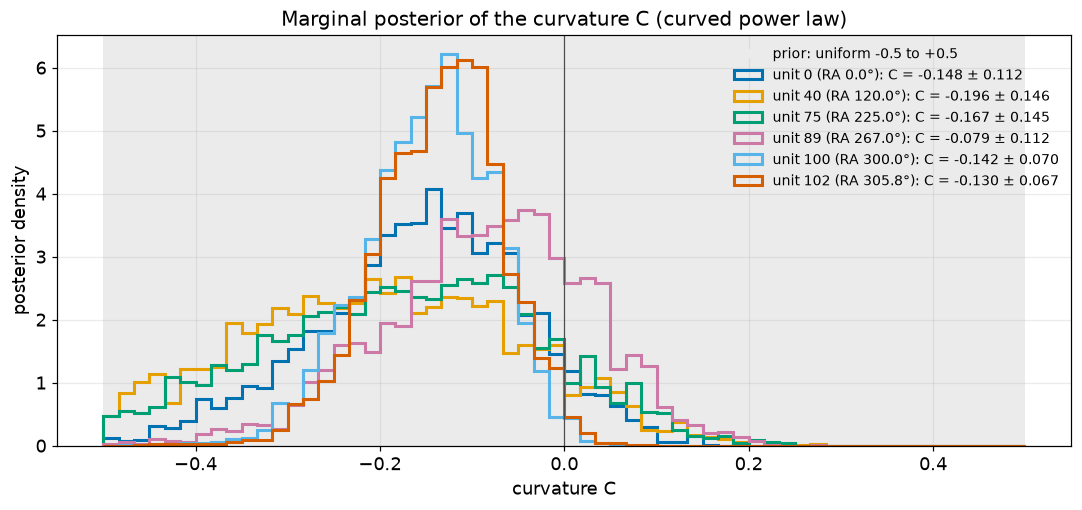

saved model_comparison/diagnostic_plots/fig7_C_posterior.png


In [80]:
if not P2_UNITS:
    print("Figure 7 skipped: no Part 2 results (set RUN_RERUNS = True).")
else:
    names = [str(n) for n in P2[CURVED][P2_UNITS[0]]["names"]]; ic = names.index("C")
    lo_c, hi_c = cfg["priors"]["C"]["low"], cfg["priors"]["C"]["high"]
    fig, ax = plt.subplots(figsize=(10, 4.8))
    ax.axvspan(lo_c, hi_c, color="0.92", lw=0, label=f"prior: uniform {lo_c:+g} to {hi_c:+g}")
    bins = np.linspace(lo_c, hi_c, 61)
    for u, c in zip(P2_UNITS, UNIT_COLS):
        smp = P2[CURVED][u]["samples"][:, ic]
        ax.hist(smp, bins=bins, density=True, histtype="step", lw=2, color=c,
                label=f"unit {u} (RA {RA_OF[u]:.1f}°): C = {np.median(smp):+.3f} ± {np.std(smp):.3f}")
    ax.axvline(0, color="0.3", lw=0.8)
    ax.set_xlim(lo_c - 0.05, hi_c + 0.05); ax.set_xlabel("curvature C"); ax.set_ylabel("posterior density")
    ax.legend(frameon=False, fontsize=9); ax.grid(alpha=0.25)
    ax.set_title("Marginal posterior of the curvature C (curved power law)")
    fig.tight_layout()
    save(fig, "fig7_C_posterior")

# Part 3 — prior sensitivity of the curvature

The curved power law is rerun with the C prior narrowed from ±0.5 (config) to ±0.2 and ±0.1. The
prior is overridden here only; `config.yaml` is not edited. The ±0.5 points and the power-law reference
are taken from Part 2's cache, and are computed only if missing.

In [81]:
P3_READY = False
if not RUN_PRIOR_SENSITIVITY and not any(cache_path(u, CURVED, f"C{w:g}").exists()
                                         for u in SENS_UNITS for w in C_HALF_WIDTHS if w != 0.5):
    print("PART 3 SKIPPED: no cached prior-sensitivity runs and RUN_PRIOR_SENSITIVITY = False. "
          "Set it to True in the settings cell to run units", SENS_UNITS)
else:
    ref = get_results(SENS_UNITS, PL, "base", cfg["priors"], RUN_PRIOR_SENSITIVITY)
    sens = {}
    for w in C_HALF_WIDTHS:
        pri = copy.deepcopy(cfg["priors"])
        pri["C"] = {"type": "uniform", "low": -w, "high": w}
        tag = "base" if w == 0.5 else f"C{w:g}"
        sens[w] = get_results(SENS_UNITS, CURVED, tag, pri, RUN_PRIOR_SENSITIVITY)
    S3_UNITS = [u for u in SENS_UNITS if u in ref and all(u in sens[w] for w in C_HALF_WIDTHS)]
    P3_READY = bool(S3_UNITS)
    if not P3_READY:
        print("Part 3: incomplete cache, nothing to plot.")

### Figure 8 — curved-model evidence against the width of the C prior
Each line is one ring sample: lnZ(curved) − lnZ(power law) as the C prior is narrowed. If the curvature
is not needed, a narrower prior raises the curved model's evidence towards the power law's; if the data
need |C| beyond the prior, it falls.

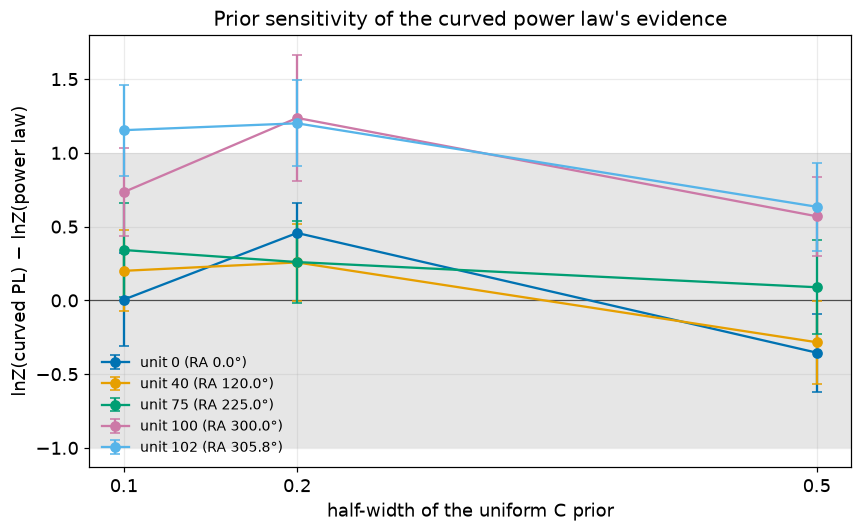

saved model_comparison/diagnostic_plots/fig8_prior_sensitivity_C.png
     C ±0.5  C ±0.2  C ±0.1
0     -0.36    0.46    0.00
40    -0.28    0.26    0.20
75     0.09    0.26    0.34
100    0.57    1.24    0.73
102    0.63    1.20    1.15

Sign of ΔlnZ flips with the prior width for: unit 0, unit 40


In [82]:
if not P3_READY:
    print("Figure 8 skipped: no Part 3 results (set RUN_PRIOR_SENSITIVITY = True).")
else:
    W = np.array(C_HALF_WIDTHS)
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.axhspan(-TIE, TIE, color="0.9", lw=0); ax.axhline(0, color="0.3", lw=0.8)
    rows, flips = {}, []
    for u, c in zip(S3_UNITS, UNIT_COLS):
        d = np.array([float(sens[w][u]["logz"]) - float(ref[u]["logz"]) for w in W])
        e = np.array([np.hypot(float(sens[w][u]["logzerr"]), float(ref[u]["logzerr"])) for w in W])
        ax.errorbar(W, d, yerr=e, fmt="o-", color=c, capsize=3, label=f"unit {u} (RA {RA_OF[u]:.1f}°)")
        rows[u] = d
        if np.any(np.sign(d) != np.sign(d[0])):
            flips.append(u)
    ax.set_xlabel("half-width of the uniform C prior"); ax.set_ylabel("lnZ(curved PL) − lnZ(power law)")
    ax.set_xticks(W); ax.legend(frameon=False, fontsize=9); ax.grid(alpha=0.25)
    ax.set_title("Prior sensitivity of the curved power law's evidence")
    fig.tight_layout()
    save(fig, "fig8_prior_sensitivity_C")
    print(pd.DataFrame(rows, index=[f"C ±{w:g}" for w in W]).T.round(2).to_string())
    print("\nSign of ΔlnZ flips with the prior width for:", ", ".join(f"unit {u}" for u in flips) if flips else "no unit")

# Part 4 — is the evidence converged?

ln Z comes from a sampler, so it is only an estimate. Four plain checks, each on the three ring samples
in `CONV_UNITS` and all four models, with the same data and priors as the model comparison:

1. **Exact answer.** For models with 2–4 parameters the evidence can be computed directly:
   ln Z = ln ∫ likelihood × prior, summed on a fine grid. UltraNest should land within its quoted error.
2. **Repeat runs.** The same run with 5 different random seeds. The spread should be about the quoted error.
3. **More or fewer live points, stricter stopping.** 100, 400 (the default) and 1600 live points, and
   stopping at dlogz 0.1 instead of 0.5. ln Z should not drift.
4. **Does the conclusion change?** The model comparison only uses ΔlnZ (model − power law) and the
   ±1 tie band. If every run gives the same verdict, the sampling noise does not matter.

Every run is seeded (UltraNest draws from numpy's global random generator) and cached in
`diagnostic_plots/cache/convergence/`. The tables are also saved as CSV in `diagnostic_plots/`.

In [83]:
CONV_DIR = CACHE_DIR / "convergence"
DEFAULT_LIVE, DEFAULT_DLOGZ = int(SCFG["min_num_live_points"]), float(SCFG["dlogz"])
SETTINGS = ([("seed", DEFAULT_LIVE, DEFAULT_DLOGZ, sd) for sd in CONV_SEEDS]
            + [("live", L, DEFAULT_DLOGZ, CONV_SEEDS[0]) for L in CONV_LIVE]
            + [("dlogz", DEFAULT_LIVE, CONV_STRICT_DLOGZ, CONV_SEEDS[0])])
REF = ("seed", DEFAULT_LIVE, DEFAULT_DLOGZ, CONV_SEEDS[0])   # the default run

def setting_label(st):
    kind, L, dz, sd = st
    if kind == "seed":
        return f"seed {sd}"
    if kind == "live":
        return f"{L} live points"
    return f"dlogz {dz:g}"

def conv_path(u, m, L, dz, sd):
    return CONV_DIR / f"unit{u:03d}__{slug(m)}__{TAG[m]}__L{L}_d{dz:g}_s{sd}.npz"

def run_setting(m, nu, t, s, L, dz, sd):
    # The same likelihood and UltraNest call as rc.log_evidence, with explicit live points, dlogz and seed.
    import ultranest
    names, fn = MODELS[m]
    transform = prior_transform(names, cfg["priors"])
    norm = -np.sum(np.log(s * np.sqrt(2 * np.pi)))
    def loglike(params):
        r = (t - fn(nu, params)) / s
        return -0.5 * np.sum(r * r, axis=-1) + norm
    np.random.seed(sd)
    sampler = ultranest.ReactiveNestedSampler(names, loglike, transform, vectorized=True, log_dir=None)
    logging.getLogger("ultranest").setLevel(logging.WARNING)
    res = sampler.run(min_num_live_points=L, dlogz=dz, show_status=False, viz_callback=False)
    return dict(logz=res["logz"], logzerr=res["logzerr"], ncall=res["ncall"], samples=res["samples"])

def grid_logz(m, nu, t, s, samples, n, width=8.0):
    # ln ∫ L x prior on an n^d grid aligned with the posterior's correlation axes (±width sigma).
    # Parameters with a log-uniform prior are integrated in ln(value), where their prior is flat.
    names, fn = MODELS[m]; d = len(names); P = cfg["priors"]
    is_log = np.array([P[k]["type"] == "loguniform" for k in names])
    lo = np.array([np.log(P[k]["low"]) if g else P[k]["low"] for k, g in zip(names, is_log)])
    hi = np.array([np.log(P[k]["high"]) if g else P[k]["high"] for k, g in zip(names, is_log)])
    x = np.array(samples, dtype=float); x[:, is_log] = np.log(x[:, is_log])
    mu, chol = x.mean(0), np.linalg.cholesky(np.cov(x.T))
    u1 = np.linspace(-width, width, n)
    X = mu + np.stack([g.ravel() for g in np.meshgrid(*[u1] * d, indexing="ij")], -1) @ chol.T
    inside = np.all((X >= lo) & (X <= hi), axis=1)          # outside the prior: zero
    theta = X[inside].copy(); theta[:, is_log] = np.exp(theta[:, is_log])
    norm = -np.sum(np.log(s * np.sqrt(2 * np.pi)))
    ll = np.full(len(X), -np.inf)
    ll[inside] = np.concatenate([-0.5 * np.sum(((t - fn(nu, theta[k:k + 200000])) / s) ** 2, axis=-1) + norm
                                 for k in range(0, len(theta), 200000)])
    ll = ll.reshape([n] * d); top = ll.max(); L = np.exp(ll - top)
    for _ in range(d):
        L = np.trapezoid(L, u1, axis=-1)
    return float(np.log(L) + top - np.sum(np.log(hi - lo)) + np.log(abs(np.linalg.det(chol))))

def grid_ns(m):
    # (coarse, fine) grid points per axis for model m, from GRID_N by its number of parameters
    return GRID_N[len(MODELS[m][0])]

def exact(u, m):
    # the exact ln Z: the finer grid
    return GRID[(u, m)][grid_ns(m)[-1]]

CONV, GRID = {}, {}
def conv_cached(path):
    # A cached run counts only if it was made from the current ring TODs.
    if not path.exists():
        return None
    z = np.load(path, allow_pickle=False)
    return {k: z[k] for k in z.files} if "tod_key" in z.files and str(z["tod_key"]) == TOD_KEY else None

have = all(conv_cached(conv_path(u, m, *st[1:])) is not None for u in CONV_UNITS for m in MODELS for st in SETTINGS)
if not (RUN_CONVERGENCE or have):
    print("PART 4 SKIPPED: set RUN_CONVERGENCE = True in the settings cell.")
else:
    CONV_DIR.mkdir(parents=True, exist_ok=True)
    pts = {u: (P2[PL][u]["nu"], P2[PL][u]["t"], P2[PL][u]["s"]) if u in P2[PL] else unit_points([u])[u][:3]
           for u in CONV_UNITS}
    for u in CONV_UNITS:
        nu, t, s = pts[u]
        for m in MODELS:
            for st in SETTINGS:
                path = conv_path(u, m, *st[1:])
                r = conv_cached(path)
                if r is None:
                    r = dict(run_setting(m, nu, t, s, *st[1:]), tod_key=TOD_KEY); np.savez(path, **r)
                CONV[(u, m, st)] = r
            GRID[(u, m)] = {n: grid_logz(m, nu, t, s, CONV[(u, m, REF)]["samples"], n) for n in grid_ns(m)}
    print(f"{len(CONV)} UltraNest runs ({len(CONV_UNITS)} samples x {len(MODELS)} models x {len(SETTINGS)} settings), "
          f"{len(GRID)} grid integrals")

96 UltraNest runs (3 samples x 4 models x 8 settings), 12 grid integrals


### Check 1 — UltraNest against the exact integral
`grid` is the exact ln Z at two grid resolutions (`grid points per axis`: 41 and 81 for 2–3 parameters,
25 and 41 for the 4-parameter order-3 model): if the coarse and fine columns agree, the grid has converged.
`UltraNest − grid` should be about the size of the quoted error or smaller.

In [84]:
if CONV:
    rows = []
    for u in CONV_UNITS:
        for m in MODELS:
            r = CONV[(u, m, REF)]
            g = exact(u, m); nc, nf = grid_ns(m)
            rows.append({"sample": u, "RA [deg]": RA_OF[u], "model": SHORT[m],
                         "UltraNest ln Z": float(r["logz"]), "quoted error": float(r["logzerr"]),
                         "grid points per axis": f"{nc} / {nf}",
                         "grid ln Z (coarse)": GRID[(u, m)][nc], "grid ln Z (fine)": g,
                         "UltraNest − grid": float(r["logz"]) - g})
    T1 = pd.DataFrame(rows)
    T1.to_csv(PLOT_DIR / "convergence_check1_exact.csv", index=False)
    print(T1.round(3).to_string(index=False))
    gconv = max(abs(GRID[k][grid_ns(k[1])[0]] - GRID[k][grid_ns(k[1])[-1]]) for k in GRID)
    worst = T1.loc[T1["UltraNest − grid"].abs().idxmax()]
    print(f"\nGrid resolution changes ln Z by at most {gconv:.3f}.")
    print(f"Largest |UltraNest − grid| = {abs(worst['UltraNest − grid']):.2f} "
          f"(sample {worst['sample']}, {worst['model']}; quoted error {worst['quoted error']:.2f}).")
    print(f"UltraNest within its quoted error of the exact value in "
          f"{int((T1['UltraNest − grid'].abs() <= T1['quoted error']).sum())} of {len(T1)} cases.")

 sample  RA [deg]              model  UltraNest ln Z  quoted error grid points per axis  grid ln Z (coarse)  grid ln Z (fine)  UltraNest − grid
      0      0.00          power law         -14.909         0.164              41 / 81             -14.868           -14.868            -0.041
      0      0.00          curved PL         -15.217         0.190              41 / 81             -15.190           -15.189            -0.027
      0      0.00 moment (2nd order)         -15.528         0.181              41 / 81             -15.681           -15.681             0.153
      0      0.00 moment (3rd order)         -15.658         0.245              25 / 41             -15.718           -15.714             0.056
     89    267.00          power law         -13.975         0.234              41 / 81             -14.024           -14.024             0.050
     89    267.00          curved PL         -14.969         0.305              41 / 81             -15.126           -15.126           

### Check 2 — the same run with five seeds
`spread` is the largest minus the smallest ln Z over the five runs, `std` their standard deviation.
If `std` is about the `typical quoted error`, the quoted error is honest.

In [85]:
if CONV:
    rows = []
    for u in CONV_UNITS:
        for m in MODELS:
            z = np.array([float(CONV[(u, m, st)]["logz"]) for st in SETTINGS if st[0] == "seed"])
            e = np.array([float(CONV[(u, m, st)]["logzerr"]) for st in SETTINGS if st[0] == "seed"])
            rows.append({"sample": u, "model": SHORT[m], "mean ln Z": z.mean(), "spread": z.max() - z.min(),
                         "std": z.std(ddof=1), "typical quoted error": float(np.median(e)),
                         "mean − exact": z.mean() - exact(u, m)})
    T2 = pd.DataFrame(rows)
    T2.to_csv(PLOT_DIR / "convergence_check2_seeds.csv", index=False)
    print(T2.round(3).to_string(index=False))

 sample              model  mean ln Z  spread   std  typical quoted error  mean − exact
      0          power law    -14.941   0.277 0.112                 0.203        -0.073
      0          curved PL    -15.229   0.219 0.087                 0.190        -0.040
      0 moment (2nd order)    -15.650   0.392 0.160                 0.199         0.031
      0 moment (3rd order)    -15.754   0.251 0.113                 0.245        -0.040
     89          power law    -14.045   0.298 0.123                 0.234        -0.020
     89          curved PL    -15.122   0.254 0.099                 0.291         0.004
     89 moment (2nd order)    -15.433   0.445 0.159                 0.229        -0.085
     89 moment (3rd order)    -15.464   0.353 0.130                 0.219        -0.097
    102          power law    -17.546   0.218 0.093                 0.228         0.145
    102          curved PL    -17.189   0.261 0.099                 0.217         0.052
    102 moment (2nd order)    -1

### Check 3 — live points and stopping rule
ln Z for 100, 400 (default) and 1600 live points, and for the stricter stop, next to the exact value.
More live points should move ln Z towards the exact value, not away from it.

In [86]:
if CONV:
    cols = [st for st in SETTINGS if st[0] != "seed" or st == REF]
    cols = sorted(cols, key=lambda st: (st[0] == "dlogz", st[1]))
    rows = []
    for u in CONV_UNITS:
        for m in MODELS:
            row = {"sample": u, "model": SHORT[m]}
            for st in cols:
                row[f"{setting_label(st) if st != REF else f'{DEFAULT_LIVE} live points (default)'}"] = float(CONV[(u, m, st)]["logz"])
            row["exact (grid)"] = exact(u, m)
            rows.append(row)
    T3 = pd.DataFrame(rows)
    T3.to_csv(PLOT_DIR / "convergence_check3_settings.csv", index=False)
    with pd.option_context("display.width", 200):
        print(T3.round(3).to_string(index=False))
    calls = {setting_label(st): int(np.median([int(CONV[(u, m, st)]["ncall"]) for u in CONV_UNITS for m in MODELS]))
             for st in cols}
    print("\nlikelihood calls per run (median):", ", ".join(f"{k}: {v}" for k, v in calls.items()))

 sample              model  100 live points  400 live points (default)  1600 live points  dlogz 0.1  exact (grid)
      0          power law          -15.197                    -14.909           -14.971    -14.853       -14.868
      0          curved PL          -15.851                    -15.217           -15.085    -15.163       -15.189
      0 moment (2nd order)          -15.916                    -15.528           -15.608    -15.566       -15.681
      0 moment (3rd order)          -15.445                    -15.658           -15.751    -15.736       -15.714
     89          power law          -14.327                    -13.975           -14.028    -14.049       -14.024
     89          curved PL          -15.339                    -14.969           -15.159    -15.067       -15.126
     89 moment (2nd order)          -15.519                    -15.657           -15.337    -15.340       -15.348
     89 moment (3rd order)          -15.113                    -15.623           -15.498

### Check 4 — does the verdict change?
For curved − power law and moment (orders 2 and 3) − power law, ΔlnZ from every run (each run paired with the power-law run
at the same settings), and from the exact integral. The verdict uses the comparison's own rule:
> +1 favours the model, < −1 favours the power law, otherwise a tie.

In [87]:
def verdict(d):
    return "favours model" if d > TIE else ("favours power law" if d < -TIE else "tie")

if CONV:
    rows = []
    for u in CONV_UNITS:
        for m in (CURVED, MOMENT, MOMENT3):
            d = np.array([float(CONV[(u, m, st)]["logz"]) - float(CONV[(u, PL, st)]["logz"]) for st in SETTINGS])
            dg = exact(u, m) - exact(u, PL)
            v = pd.Series([verdict(x) for x in d]).value_counts()
            rows.append({"sample": u, "RA [deg]": RA_OF[u], "comparison": f"{SHORT[m]} − power law",
                         "exact ΔlnZ": dg, "exact verdict": verdict(dg),
                         "lowest ΔlnZ": d.min(), "highest ΔlnZ": d.max(),
                         "runs agreeing with exact": f"{int((v.get(verdict(dg), 0)))} of {len(d)}"})
    T4 = pd.DataFrame(rows)
    T4.to_csv(PLOT_DIR / "convergence_check4_verdicts.csv", index=False)
    with pd.option_context("display.width", 200):
        print(T4.round(2).to_string(index=False))

 sample  RA [deg]                     comparison  exact ΔlnZ     exact verdict  lowest ΔlnZ  highest ΔlnZ runs agreeing with exact
      0      0.00          curved PL − power law       -0.32               tie        -0.65         -0.11                   8 of 8
      0      0.00 moment (2nd order) − power law       -0.81               tie        -0.92         -0.52                   8 of 8
      0      0.00 moment (3rd order) − power law       -0.85               tie        -1.00         -0.25                   8 of 8
     89    267.00          curved PL − power law       -1.10 favours power law        -1.22         -0.97                   6 of 8
     89    267.00 moment (2nd order) − power law       -1.32 favours power law        -1.68         -1.19                   8 of 8
     89    267.00 moment (3rd order) − power law       -1.34 favours power law        -1.65         -0.79                   7 of 8
    102    305.75          curved PL − power law        0.45               tie     

### Figure 9 — ΔlnZ from every run, against the exact value
Each panel is one ring sample. Dots are the individual runs (5 seeds, other live points, stricter stop),
the bar is the exact value from the grid integral, and the grey band is the ±1 tie range.

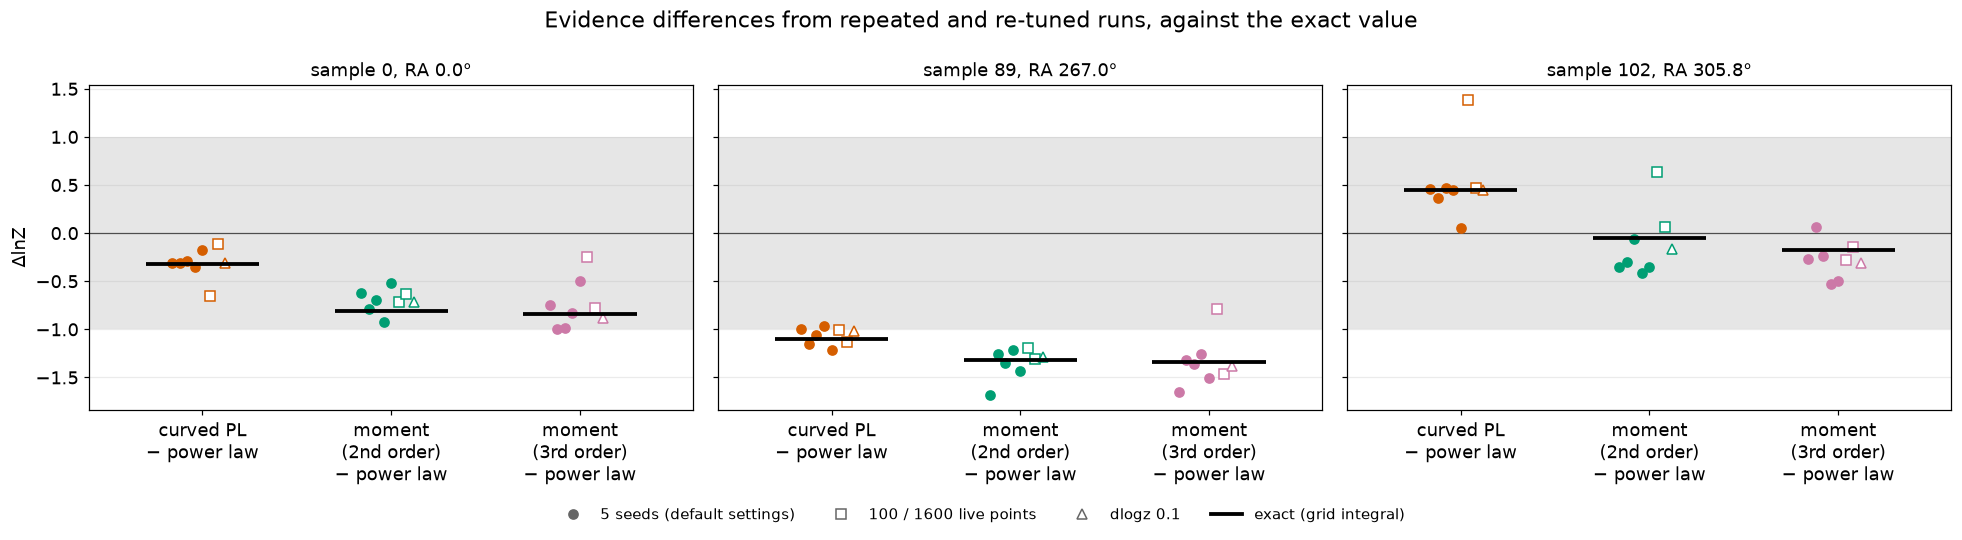

saved model_comparison/diagnostic_plots/fig9_convergence_dlogZ.png


In [88]:
if CONV:
    fig, axes = plt.subplots(1, len(CONV_UNITS), figsize=(6 * len(CONV_UNITS), 4.6), sharey=True)
    marks = {"seed": "o", "live": "s", "dlogz": "^"}
    for ax, u in zip(np.atleast_1d(axes), CONV_UNITS):
        ax.axhspan(-TIE, TIE, color="0.9", lw=0)
        ax.axhline(0, color="0.3", lw=0.8)
        for j, m in enumerate((CURVED, MOMENT, MOMENT3)):
            for k, st in enumerate(SETTINGS):
                d = float(CONV[(u, m, st)]["logz"]) - float(CONV[(u, PL, st)]["logz"])
                ax.plot(j + (k - len(SETTINGS) / 2) * 0.04, d, marks[st[0]], color=COL[m], ms=6, mfc="white" if st[0] != "seed" else COL[m])
            dg = exact(u, m) - exact(u, PL)
            ax.hlines(dg, j - 0.3, j + 0.3, color="black", lw=2.5)
        ax.set_xticks([0, 1, 2]); ax.set_xticklabels([SHORT[m].replace(" (", "\n(") + "\n− power law" for m in (CURVED, MOMENT, MOMENT3)])
        ax.set_xlim(-0.6, 2.6)
        ax.set_title(f"sample {u}, RA {RA_OF[u]:.1f}°", fontsize=12)
        ax.grid(alpha=0.25, axis="y")
    np.atleast_1d(axes)[0].set_ylabel("ΔlnZ")
    from matplotlib.lines import Line2D
    handles = [Line2D([], [], marker="o", ls="", color="0.4", label="5 seeds (default settings)"),
               Line2D([], [], marker="s", ls="", color="0.4", mfc="white", label="100 / 1600 live points"),
               Line2D([], [], marker="^", ls="", color="0.4", mfc="white", label=f"dlogz {CONV_STRICT_DLOGZ:g}"),
               Line2D([], [], color="black", lw=2.5, label="exact (grid integral)")]
    fig.legend(handles=handles, loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.06))
    fig.suptitle("Evidence differences from repeated and re-tuned runs, against the exact value")
    fig.tight_layout()
    save(fig, "fig9_convergence_dlogZ")

### Part 4 in plain numbers

*These numbers are from the 2026-10-27 run (native TODs, three models, before the order-3 moment
expansion was added). Rerun Part 4 and update them from the tables above.*

Run on 2026-10-27; samples 0 (RA 0°), 89 (RA 267°) and 102 (RA 305.8°); 72 UltraNest runs; tables in
`diagnostic_plots/convergence_check*.csv`.

* **The exact integral is reliable.** Doubling the grid (41 → 81 points per axis) changes ln Z by less than 0.001.
* **UltraNest is close to exact.** At the default settings it is off by 0.00 to 0.28 in ln Z (worst: sample 0,
  power law, −0.28 against a quoted error of 0.25). It is within its quoted error in 7 of 9 cases and just
  outside in the other 2.
* **The quoted error is honest, slightly generous.** Over 5 seeds the scatter (std) is 0.05–0.20, against a typical
  quoted error of 0.21–0.31. The mean of the 5 runs is within 0.15 of the exact value in every case.
* **Settings do not bias it.** 100, 400 and 1600 live points and the stricter stop (dlogz 0.1) all land within
  about ±0.4 of the exact value, with no drift in one direction. 1600 live points cost about 3.5× the likelihood
  calls of the default.
* **The verdicts hold, except right at the ±1 line.** In 5 of the 6 comparisons every run gives the exact
  verdict (8 of 8). The exception is sample 0, moment − power law: the exact ΔlnZ is −0.88, just inside the tie
  band, and 3 of the 8 runs fall just below −1 (lowest −1.25). So a ΔlnZ within about ±0.4 of ±1 should be read
  as borderline, not as a clear verdict.
* **Sampling noise is far smaller than the effects that matter.** The Cygnus result (sample 102: curved − power law
  +4.06 exact, 3.71 to 4.63 over all runs) and the power-law preference at RA 267° (−1.53 exact) are unaffected.


# Summary

**What was looked at.** Part 1 reads the saved per-sample evidences of the 2026-10-21 run
(`evidence_per_unit_tod.csv`, published survey error bars, no placeholders). Every one of the 120
ring samples has the same 6 points. Each ln Z carries a sampling error of about ±0.27, so a
difference between two models is uncertain by about ±0.37. Parts 2 and 3 have not been run yet
(both flags off, nothing cached).

**Findings, in plain language.**

* **Curved power law vs power law: mostly a tie.** In 98 of 120 samples the two cannot be told
  apart (|ΔlnZ| ≤ 1); the median difference is −0.19.
* **The curved model wins only around Cygnus A.** It is favoured in 12 samples: nine between
  RA 294° and 318°, peaking at +4.35 at RA 305.8° (6 of them strongly, > 2), and three weakly near
  RA 75–84°. Cygnus A is at RA 299.9°.
* **Just before Cygnus the power law is preferred.** In 10 samples between RA 231° and 282°
  the curved model is worse by 1–2 (lowest −1.96 at RA 267°).
* **The moment expansion is usually worse than the power law.** It loses by more than 1 in 65
  samples (median −1.07) and wins only in the 7 samples at RA 297–315°, the same Cygnus region.
* **The moment expansion is never preferred over the curved power law.** They tie in 86 samples
  and the curved model wins in 34. With the same curvature prior range, the two models differ only
  at third order and beyond, so this gap is mostly how their priors spread over the data.
* **No sums.** Neighbouring ring samples share most of the beam, so the counts above are not
  120 independent votes; a summed ln Z would overstate the evidence many times over.

**What this means.** On the current data and error bars, a single power law is enough for most of the
TRIS ring, and curvature is supported only where the beam crosses the Galactic plane at Cygnus.
Whether that is genuine spectral curvature or a mismatch at the brightest, most structured part of
the sky (beam, error bars, the Maipu offset in TODO N-16) is what Parts 2 and 3 are set up to check:
Part 2 shows the fits and separates fit quality from the Occam penalty, Part 3 tests how much the
curved model's evidence depends on the C prior.